# The single-loss approximation, its mean correction and the infinite-mean zone

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 03 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state the single-loss approximation of the 99.9% annual-loss quantile and say why it works for heavy tails;
- derive the Poisson, generalised Pareto closed form and verify that it scales like $\lambda^{\xi}$;
- compare the approximation and its mean-corrected form with the committed true quantile for four tail indices, and say which of the two forms the engine marks as unverified;
- explain why the mean, the mean correction and the expected shortfall do not exist at a tail index of 1 or more, and see the engine refuse to compute them.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate, distributions, sla

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are the four variants of case C17, one per tail index (0.6, 0.8, 0.96 and 1.1) of the synthetic bank. Each document states the true frequency and severity of the generator and the 99.9% quantile of the true annual loss computed by four methods.

- **Files read:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` and `xi-1-1.json`, the blocks `outputs.truth` (the generator's true parameters and, when it exists, the true mean annual loss), `outputs.exceedance.quantile_999_eur` (the quantile by Monte Carlo, Panjer, Fourier and the single-loss approximation) and `outputs.cells` (the estimates over 1,000 simulated histories).
- **What is committed and what is not:** the true quantile is the Fourier one on a fine grid, checked by Monte Carlo. The mean and the expected shortfall are committed only where they exist: for the variant with tail index 1.1 the document states no mean and the reason.

The next cell loads the four documents and prints, for each, the true parameters and the committed mean annual loss.

In [2]:
# Load the four variant documents and read the true parameters of each
ROOT = Path("../../..").resolve()
docs = {name: json.loads((ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")}
truth = {}
for name, doc in docs.items():
    t = doc["outputs"]["truth"]
    truth[name] = {"lam": t["frequency"]["lambda_per_year"], "par": (t["severity"]["tail_index"], t["severity"]["scale_eur"], t["severity"]["location_eur"]),
                   "q": doc["outputs"]["exceedance"]["quantile_999_eur"], "mean": t["annual_loss_mean"]["value_eur"]}
    mean_text = format(t["annual_loss_mean"]["value_eur"], ",.0f") if t["annual_loss_mean"]["value_eur"] is not None else "none (infinite mean)"
    print("%-8s lambda = %8.4f | xi = %-4s | beta = %10.2f | committed mean annual loss (EUR): %s" % (name, truth[name]["lam"], truth[name]["par"][0], truth[name]["par"][1], mean_text))

xi-0-6   lambda =  59.1602 | xi = 0.6  | beta =   24381.85 | committed mean annual loss (EUR): 4,197,691
xi-0-8   lambda =  65.2849 | xi = 0.8  | beta =   17744.21 | committed mean annual loss (EUR): 6,444,989
xi-0-96  lambda =  73.3821 | xi = 0.96 | beta =   12823.68 | committed mean annual loss (EUR): 24,259,548
xi-1-1   lambda =  85.7071 | xi = 1.1  | beta =    8797.32 | committed mean annual loss (EUR): none (infinite mean)


## Method

### Step 1: the approximation

For a severity with a heavy (subexponential) tail the probability that the annual loss exceeds a high amount is, to first order, the probability that **one single loss** does so, times the expected number of losses (Embrechts, Kluppelberg and Mikosch, 1997, cited by Shevchenko, 2010, equation 69):

$$P(Z > z) \sim E[N]\, \big(1 - F(z)\big), \qquad z \to \infty$$

Setting the right side equal to $1 - \alpha$ and solving for $z$ gives the single-loss approximation of the value at risk (Shevchenko, 2010, equation 70):

$$\mathrm{VaR}_\alpha[Z] \;\approx\; F^{-1}\!\left(1 - \frac{1 - \alpha}{E[N]}\right)$$

The big loss of a bad year is the whole story, which is why it needs no grid and no simulation. The engine's `sla_var` takes the mean count, the severity law and the level. It raises when $E[N] \le 1 - \alpha$, because then the argument of $F^{-1}$ would leave $(0, 1)$. The next cell first checks the formula on the benchmark of notebook 03 (Poisson(100), lognormal(0, 2)) against its exact quantile, and then applies it to the four variants of the bank.

In [3]:
# The approximation on the benchmark (exact quantile 5,849) and on the four variants, against the committed true quantile
approx_benchmark = sla.sla_var(100.0, "lognormal", (0.0, 2.0), 0.999)
print("benchmark: approximation %.2f | exact quantile 5849 | ratio %.3f" % (approx_benchmark, approx_benchmark / 5849.0))
print()
print("%-8s %16s %16s %16s %8s %12s" % ("", "approximation", "committed", "true (Fourier)", "ratio", ""))
for name, t in truth.items():
    value = sla.sla_var(t["lam"], "gpd", t["par"], 0.999)
    print("%-8s %16s %16s %16s %8.4f" % (name, format(value, ",.0f"), format(t["q"]["sla"], ",.0f"), format(t["q"]["fft"], ",.0f"), value / t["q"]["fft"]))
print("baked by riskvalidation", docs["xi-0-8"]["provenance"]["riskvalidation_version"], "| installed", md.version("riskvalidation"))

benchmark: approximation 5063.34 | exact quantile 5849 | ratio 0.866

            approximation        committed   true (Fourier)    ratio             
xi-0-6         29,626,777       29,626,777       33,897,000   0.8740
xi-0-8        157,682,341      157,682,341      163,483,000   0.9645
xi-0-96       626,189,605      626,189,607      634,865,452   0.9863
xi-1-1      2,134,402,639    2,134,402,640    2,148,602,460   0.9934
baked by riskvalidation 0.7.0 | installed 0.9.0


### Step 2: the closed form for a Poisson count and a generalised Pareto severity

With the generalised Pareto survival $1 - F(x) = \big(1 + \xi (x - u)/\beta\big)^{-1/\xi}$ and $E[N] = \lambda$, setting $\lambda (1 - F(z)) = 1 - \alpha$ and solving gives

$$\mathrm{VaR}_\alpha[Z] \;\approx\; u + \frac{\beta}{\xi}\left[\left(\frac{\lambda}{1 - \alpha}\right)^{\xi} - 1\right]$$

The quantity $\mathrm{VaR} - u + \beta/\xi = (\beta/\xi)\,(\lambda/(1-\alpha))^{\xi}$ is proportional to $\lambda^{\xi}$: doubling the expected number of losses multiplies it by $2^{\xi}$, not by 2. With a tail index below 1, capital grows **less than in proportion** to the number of losses. `sla_var_poisson_gpd` implements it. The next cell compares it with the general `sla_var` and checks the scaling by doubling $\lambda$.

In [4]:
# The closed form against the general function, and the scaling by lambda to the power xi
print("%-8s %18s %18s %14s %10s" % ("", "sla_var", "closed form", "x2 lambda", "2^xi"))
for name, t in truth.items():
    xi, beta, u = t["par"]
    general = sla.sla_var(t["lam"], "gpd", t["par"], 0.999)
    closed = sla.sla_var_poisson_gpd(t["lam"], xi, beta, 0.999, u)
    shifted = lambda lam: sla.sla_var_poisson_gpd(lam, xi, beta, 0.999, u) - u + beta / xi
    print("%-8s %18s %18s %14.6f %10.6f" % (name, format(general, ",.2f"), format(closed, ",.2f"), shifted(2 * t["lam"]) / shifted(t["lam"]), 2 ** xi))

                    sla_var        closed form      x2 lambda       2^xi
xi-0-6        29,626,777.12      29,626,777.12       1.515717   1.515717
xi-0-8       157,682,341.09     157,682,341.09       1.741101   1.741101
xi-0-96      626,189,605.20     626,189,605.20       1.945310   1.945310
xi-1-1     2,134,402,638.86   2,134,402,638.86       2.143547   2.143547


### Step 3: the mean correction, which the engine marks as unverified

The first-order approximation ignores the other losses of the bad year. A refinement adds their expected total, the mean annual loss $E[N]\,E[X]$ (Bocker and Sprittulla, 2006; Degen, 2010):

$$\mathrm{VaR}^{\text{corr}}_\alpha[Z] \;\approx\; F^{-1}\!\left(1 - \frac{1 - \alpha}{E[N]}\right) + E[N]\, E[X]$$

The research behind the engine records that this commonly quoted form **was not checked against either primary text**, and `sla_var_mean_corrected` says so in its result: `status` is the word `UNVERIFIED` every time. Use it as a comparison, not as a validated formula. It needs the severity mean, so it raises for a tail index of 1 or more. The next cell computes it for each variant, shows the added term, which for a Poisson count equals the true mean annual loss the document commits, and the ratio to the true quantile.

In [5]:
# The mean-corrected form for each variant; the variant with an infinite mean is refused by the engine
for name, t in truth.items():
    try:
        result = sla.sla_var_mean_corrected(t["lam"], "gpd", t["par"], 0.999)
    except ValueError:
        print("%-8s refused: the severity has no mean (tail index 1 or more), so the correction does not exist; E[X] = %s" % (name, distributions.severity_moment("gpd", t["par"], 1)))
        continue
    print("%-8s first order %14s + mean %12s = %14s | status %s | ratio to the truth %.4f | committed mean %s"
          % (name, format(result.var_first_order, ",.0f"), format(result.mean_correction, ",.0f"), format(result.var, ",.0f"), result.status, result.var / t["q"]["fft"], format(t["mean"], ",.0f")))

xi-0-6   first order     29,626,777 + mean    4,197,691 =     33,824,468 | status UNVERIFIED | ratio to the truth 0.9979 | committed mean 4,197,691
xi-0-8   first order    157,682,341 + mean    6,444,989 =    164,127,330 | status UNVERIFIED | ratio to the truth 1.0039 | committed mean 6,444,989
xi-0-96  first order    626,189,605 + mean   24,259,547 =    650,449,153 | status UNVERIFIED | ratio to the truth 1.0245 | committed mean 24,259,548
xi-1-1   refused: the severity has no mean (tail index 1 or more), so the correction does not exist; E[X] = inf


### Step 4: the expected shortfall, where it exists and where it does not

The expected shortfall at level $\alpha$ averages the losses beyond the quantile and needs the mean of the annual loss to exist. For a tail index of 1 or more it does not. `es_from_pmf` reads a probability grid and refuses a grid that does not carry the tail; its documentation warns that the grid alone cannot reveal an infinite mean, because on a coarse enough grid the missing mass of such a severity can fall below the tolerance and a finite, meaningless number would come out. So `es_for_severity` asks the severity first, with `severity_moment`, and raises before computing anything. The next cell computes the expected shortfall of the variant with tail index 0.6 on a Fourier grid that carries the tail (step EUR 40,000, 65,536 points), and then asks for it for the variant with tail index 1.1.

In [6]:
# The expected shortfall for tail index 0.6 on a grid that carries the tail, then for tail index 1.1
t06 = truth["xi-0-6"]
STEP_ES, POINTS_ES = 40_000.0, 65_536
f_es = aggregate.discretise_severity("gpd", t06["par"], STEP_ES, POINTS_ES)
h_es = aggregate.fft_aggregate("poisson", (t06["lam"],), f_es, padding_factor=4)
var_es = aggregate.quantile_from_pmf(h_es, STEP_ES, 0.999)
es = aggregate.es_for_severity(h_es, STEP_ES, 0.999, "gpd", t06["par"])
print("xi = 0.6 | mass beyond the grid %.2e | VaR 99.9%% EUR %s | ES 99.9%% EUR %s | ES/VaR %.2f" % (1.0 - h_es.sum(), format(var_es, ",.0f"), format(es, ",.0f"), es / var_es))
t11 = truth["xi-1-1"]
try:
    aggregate.es_for_severity(h_es, STEP_ES, 0.999, "gpd", t11["par"])
except ValueError:
    print("xi = 1.1 | E[X] =", distributions.severity_moment("gpd", t11["par"], 1), "| the engine refuses: the expected shortfall does not exist")

xi = 0.6 | mass beyond the grid 5.72e-07 | VaR 99.9% EUR 33,800,000 | ES 99.9% EUR 74,526,123 | ES/VaR 2.20
xi = 1.1 | E[X] = inf | the engine refuses: the expected shortfall does not exist


### Step 5: where the approximation fails

Two limits. First, it is an asymptotic statement for heavy tails; for a light tail it can be far off at practical levels, a point Shevchenko (2010) makes for a lognormal with $\sigma = 1$. The next cell compares it with the exact quantile (Panjer on a fine grid) for Poisson(100) and lognormal(0, 1). Second, it needs $E[N] > 1 - \alpha$: with fewer than one loss per thousand years the quantile level is below the support of one loss and the engine raises. The cell shows both.

In [7]:
# A light-tailed severity, where the approximation is poor, and a mean count too small for the level
f_light = aggregate.discretise_severity("lognormal", (0.0, 1.0), 0.05, 20_000)
h_light = aggregate.panjer_recursion("poisson", (100.0,), f_light)
exact_light = aggregate.quantile_from_pmf(h_light, 0.05, 0.999)
approx_light = sla.sla_var(100.0, "lognormal", (0.0, 1.0), 0.999)
print("LN(0, 1), Poisson(100): exact (Panjer) %.2f | approximation %.2f | ratio %.3f" % (exact_light, approx_light, approx_light / exact_light))
try:
    sla.sla_var(0.0005, "gpd", truth["xi-0-8"]["par"], 0.999)
except ValueError:
    print("E[N] = 0.0005 <= 1 - 0.999: the engine raises, the approximation is undefined")

LN(0, 1), Poisson(100): exact (Panjer) 270.20 | approximation 71.16 | ratio 0.263
E[N] = 0.0005 <= 1 - 0.999: the engine raises, the approximation is undefined


### Step 6: from the formula to an estimate

Everything above used the **true** parameters. A bank has only a history, and the committed cells estimate the approximation, and its mean-corrected form, on 1,000 independent histories of 10 years with a collection threshold of EUR 20,000, by fitting a generalised Pareto to the recorded losses and the Poisson rate to the counts. The next cell prints, for each variant, how many of the 1,000 histories give a value, the median of the estimate over the truth, the share of histories that underestimate, and the interquartile range over the truth. The figure that follows compares the approximation with the truth for each tail index, with true parameters and as estimated.

In [8]:
# Read the committed estimates of the approximation on 1,000 histories of 10 years (threshold EUR 20,000)
estimates = {}
for name, doc in docs.items():
    capital = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")["capital"]
    for rung in ("sla", "sla_mean_corrected"):
        block = capital[rung] if "n_defined" in capital[rung] else capital[rung]["summary"]
        estimates[(name, rung)] = block
        if block is None:
            print("%-8s %-20s not defined: infinite mean" % (name, rung))
            continue
        print("%-8s %-20s defined %4d | median / truth %.3f | underestimate share %.3f | IQR / truth %.3f"
              % (name, rung, block["n_defined"], block["ratio_to_truth"]["median"], block["share_underestimating"], block["iqr_over_truth"]))

xi-0-6   sla                  defined 1000 | median / truth 0.800 | underestimate share 0.627 | IQR / truth 0.730
xi-0-6   sla_mean_corrected   defined 1000 | median / truth 0.917 | underestimate share 0.547 | IQR / truth 0.746
xi-0-8   sla                  defined 1000 | median / truth 0.963 | underestimate share 0.520 | IQR / truth 1.020
xi-0-8   sla_mean_corrected   defined  988 | median / truth 0.983 | underestimate share 0.506 | IQR / truth 0.997
xi-0-96  sla                  defined 1000 | median / truth 0.975 | underestimate share 0.514 | IQR / truth 1.178
xi-0-96  sla_mean_corrected   defined  683 | median / truth 0.715 | underestimate share 0.716 | IQR / truth 0.597
xi-1-1   sla                  defined 1000 | median / truth 1.002 | underestimate share 0.499 | IQR / truth 1.441
xi-1-1   sla_mean_corrected   not defined: infinite mean


The last cell draws the comparison. On the left, the ratio of each form to the true 99.9% quantile for the four tail indices with the true parameters: the first-order form sits below the truth and approaches it as the tail index grows, and the mean-corrected form, where it exists, lies within 0.2% to 2.5% of it. On the right, the estimates from histories: the median stays near the formula, but the 25% to 75% band over the truth is about as wide as the truth itself or wider, which is the subject of the level 4 notebook of this topic.

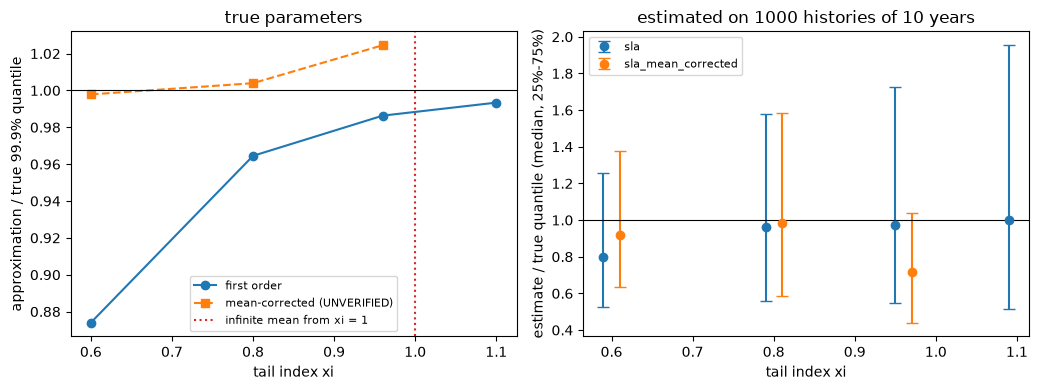

In [9]:
# Draw the ratios to the truth: with true parameters, and estimated on 1,000 histories
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
xis = [truth[n]["par"][0] for n in truth]
first_order = [sla.sla_var(t["lam"], "gpd", t["par"], 0.999) / t["q"]["fft"] for t in truth.values()]
corrected = []
for t in truth.values():
    try:
        corrected.append(sla.sla_var_mean_corrected(t["lam"], "gpd", t["par"], 0.999).var / t["q"]["fft"])
    except ValueError:
        corrected.append(np.nan)
left.plot(xis, first_order, "o-", label="first order")
left.plot(xis, corrected, "s--", label="mean-corrected (UNVERIFIED)")
left.axhline(1.0, color="black", linewidth=0.8)
left.axvline(1.0, color="tab:red", linestyle=":", label="infinite mean from xi = 1")
left.set_xlabel("tail index xi")
left.set_ylabel("approximation / true 99.9% quantile")
left.set_title("true parameters")
left.legend(fontsize=8)

for rung, color, shift in (("sla", "tab:blue", -0.01), ("sla_mean_corrected", "tab:orange", 0.01)):
    xs, med, lo, hi = [], [], [], []
    for name in truth:
        block = estimates[(name, rung)]
        if block is None:
            continue
        xs.append(truth[name]["par"][0] + shift)
        med.append(block["ratio_to_truth"]["median"])
        lo.append(block["ratio_to_truth"]["p25"])
        hi.append(block["ratio_to_truth"]["p75"])
    right.errorbar(xs, med, yerr=[np.array(med) - np.array(lo), np.array(hi) - np.array(med)], fmt="o", color=color, capsize=4, label=rung)
right.axhline(1.0, color="black", linewidth=0.8)
right.set_xlabel("tail index xi")
right.set_ylabel("estimate / true quantile (median, 25%-75%)")
right.set_title("estimated on 1000 histories of 10 years")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The approximation with true parameters.** The first-order form is 0.874, 0.965, 0.986 and 0.993 of the true 99.9% quantile for tail indices 0.6, 0.8, 0.96 and 1.1: it sits below the truth and closes the gap as the tail gets heavier, which is what an asymptotic statement for heavy tails predicts. The recomputation equals the committed value to the rounding of the file, and the installed engine 0.8.1 reproduces what 0.7.0 baked.
- **The closed form and its scaling.** `sla_var_poisson_gpd` equals `sla_var` to the cent, and doubling the expected number of losses multiplies the shifted quantity by 1.516, 1.741, 1.945 and 2.144, exactly $2^{\xi}$. With a tail index below 1, capital grows less than in proportion to the frequency; above 1 it grows more.
- **The mean correction.** Adding $E[N]E[X]$ gives 0.998, 1.004 and 1.025 of the truth for the three finite-mean variants, within 2.5% of it; the added term equals the committed true mean annual loss (EUR 4.20 million, 6.44 million and 24.26 million). The engine marks the form `UNVERIFIED` in every result, because the research behind it did not check it against either primary text, so it is a comparison and not a validated formula.
- **The infinite-mean zone.** At tail index 1.1 `severity_moment` returns infinity, `sla_var_mean_corrected` raises, and `es_for_severity` raises before computing anything. At tail index 0.6, where the mean exists, a Fourier grid that carries the tail (mass beyond it 5.7e-7) gives a 99.9% expected shortfall of EUR 74.5 million, 2.20 times the value at risk of EUR 33.8 million.
- **Where it fails.** For a lognormal with sigma 1 and Poisson(100), the approximation is 71.2 against an exact 270.2, a ratio of 0.263: it is a statement about heavy tails. And with 0.0005 losses a year it is undefined for the 99.9% level, and the engine raises.
- **From a formula to an estimate.** Estimated on 10-year histories, the median of the approximation over the truth stays near the formula (0.80, 0.96, 0.98 and 1.00), but the interquartile range over the truth is 0.73, 1.02, 1.18 and 1.44, as wide as the truth or wider, and the share of histories that underestimate is 0.63 at tail index 0.6 and about one half elsewhere. The mean-corrected estimate is defined on 988 of 1,000 histories at tail index 0.8, on 683 at 0.96, and on none at 1.1, with a median of 0.715 of the truth at 0.96.

What this notebook does not show: how a bank would choose the parameters it plugs into the formula (notebook 02), or how the standardised approach answers the same question without a distribution (notebook 05).

## Summary

- The single-loss approximation reads the 99.9% annual-loss quantile as the severity quantile at $1 - (1 - \alpha)/E[N]$; for heavy tails it is within 13% of the truth at tail index 0.6 and within 1% at 1.1 with true parameters.
- For a Poisson count and a generalised Pareto severity it is a closed form that scales like $\lambda^{\xi}$.
- The mean-corrected form is closer where the mean exists but the engine marks it unverified; the mean, the correction and the expected shortfall do not exist at a tail index of 1 or more, and the engine refuses them.
- The approximation is a statement about heavy tails and needs more than one expected loss per $1 - \alpha$ years.
- Estimated on a 10-year history it is as dispersed as the quantity it estimates.

**What to try next.** Change the level to 0.99 and see how the gap to the truth moves. Draw a history as notebook 02 does, fit its Poisson rate and generalised Pareto tail, and put them into `sla_var`; compare the result with the interquartile range above. Continue with notebook 05.

## References

- Degen, M. (2010), The calculation of minimum regulatory capital using single-loss approximations, Journal of Operational Risk 5(4), 3-17. https://doi.org/10.21314/JOP.2010.084
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40 (equations 69 and 70). https://arxiv.org/abs/1008.1108 and https://doi.org/10.21314/JOP.2010.077
- Embrechts, P., Kluppelberg, C. and Mikosch, T. (1997), Modelling Extremal Events for Insurance and Finance, Springer, Theorem 1.3.9, and Bocker, K. and Sprittulla, J. (2006), Operational VaR: meaningful means, Risk, as cited by Shevchenko (2010) and by the engine's documentation of `sla_var_mean_corrected`.